In [29]:
import math, random, time, json
from copy import deepcopy
import numpy as np
import pandas as pd
import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Optimizer
import matplotlib.pyplot as plt

import torch, random, numpy as np
from torchvision import datasets, transforms
from torch.utils.data import random_split, DataLoader


## **Get the Dataset**



In [17]:

# Fix seeds
SEED = 0
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

#  Download 
root = "./data"
train_full = datasets.CIFAR10(root, train=True,  download=True, transform=transforms.ToTensor())
test_set   = datasets.CIFAR10(root, train=False, download=True, transform=transforms.ToTensor())

#  Split 45k / 5k with a seeded generator
g = torch.Generator().manual_seed(SEED)
train_set, val_set = random_split(train_full, [45000, 5000], generator=g)

# Per-channel mean/std from the 45k training images
X = torch.stack([train_set[i][0] for i in range(len(train_set))])  # (45000, 3, 32, 32)
mean = X.mean(dim=(0, 2, 3))
std  = X.std(dim=(0, 2, 3))
print("="*30, "mean/std", "="*30)
print("mean: ", mean.tolist())
print("std: ", std.tolist())

Files already downloaded and verified
Files already downloaded and verified
============================== mean/std ==============================
mean:  [0.4911963641643524, 0.48199522495269775, 0.4464317560195923]
std:  [0.24715185165405273, 0.24362300336360931, 0.26167726516723633]


## **Data Normalization**

In [12]:
def to_tensors(subset):
    xs = torch.stack([subset[i][0] for i in range(len(subset))])
    ys = torch.tensor([subset[i][1] for i in range(len(subset))])
    return (xs - mean[None, :, None, None]) / std[None, :, None, None], ys

Xtr, ytr = to_tensors(train_set)
Xva, yva = to_tensors(val_set)
Xte, yte = to_tensors(test_set)  
print("="*30, "shapes", "="*30)
print("Train: ", "Xtr: ", Xtr.shape, "ytr: ", ytr.shape)
print("Validation: ", "Xva: ", Xva.shape, "yva: ", yva.shape)
print("Test: ", "Xte: ", Xte.shape, "yte: ", yte.shape)

============================== shapes ==============================
Train:  Xtr:  torch.Size([45000, 3, 32, 32]) ytr:  torch.Size([45000])
Validation:  Xva:  torch.Size([5000, 3, 32, 32]) yva:  torch.Size([5000])
Test:  Xte:  torch.Size([10000, 3, 32, 32]) yte:  torch.Size([10000])


## **Task 01**
### 1(a): Layers with explicit forward / backward (no autograd)

In [21]:
class Linear:
    def __init__(self, n_in, n_out,init="kaiming", dtype=torch.float32, device="cpu"):
        # pick std for random weights based on init method
        if init == "kaiming":
            # for ReLU, std = sqrt(2/n_in)
            std = math.sqrt(2.0/n_in)
        elif init == "xavier":
            # for sigmoid, std = sqrt(2/(n_in+n_out))
            std = math.sqrt(2.0/(n_in+n_out))
        else:
            raise ValueError("Unknown init method: {}".format(init))
        
        self.W = torch.randn(n_out, n_in, dtype=dtype, device=device) * std
        self.b = torch.zeros(n_out, dtype=dtype, device=device)
        self.dW = torch.zeros_like(self.W)
        self.db = torch.zeros_like(self.b)
        
    def forward(self, X):
        self.X = X
        return X @ self.W.T + self.b
    
    def backward(self, dY):
        self.dW = dY.T @ self.X
        self.db = dY.sum(dim=0)
        return dY @ self.W
    
    def params(self):
        return [self.W, self.b]
    def grads(self):
        return [self.dW, self.db]
        
class ReLU:
    def forward(self, X):
        self.mask = X>0
        return X * self.mask
    def backward(self, dY):
        return dY * self.mask
    def params(self):
        return []
    def grads(self):
        return []
    
class Sigmoid:
    def forward(self, X):
        self.out = 1/(1+torch.exp(-X))
        return self.out
    def backward(self, dY):
        return dY * self.out * (1-self.out)
    def params(self):
        return []
    def grads(self):
        return []
    
class SoftmaxCrossEntropy:
    def forward(self, logits, y):
        z = logits - logits.max(dim=1, keepdim=True).values
        log_p = z - torch.log(torch.exp(z).sum(dim=1, keepdim=True))
        self.p = torch.exp(log_p)
        self.y = y
        return -log_p[torch.arange(len(y)), y].mean()
    
    def backward(self):
        dlogits = self.p.clone()
        dlogits[torch.arange(len(self.y)), self.y] -= 1.0
        return dlogits / len(self.y)

### 1(a) Assembling the MLP

In [23]:
class MLP:
    def __init__(self, sizes, act = "relu", init = "kaiming", dtype=torch.float32, device="cpu"):
        self.layers = []
        for i in range(len(sizes)-1):
            self.layers.append(Linear(sizes[i], sizes[i+1], init, dtype, device))
            if i<len(sizes)-2:
                self.layers.append(ReLU() if act == "relu" else Sigmoid())
        
        self.loss_fn = SoftmaxCrossEntropy()
        
    def logits(self, X):
        for  layer in self.layers:
            X = layer.forward(X)
        return X
    
    def loss(self, X, y):
        return self.loss_fn.forward(self.logits(X), y)
    
    def backward(self):
        d = self.loss_fn.backward()
        for layer in reversed(self.layers):
            d = layer.backward(d)
        
    def params(self):
        return [p for l in self.layers for p in l.params()]
    def grads(self):
        return [g for l in self.layers for g in l.grads()]
    def linear_layers(self): 
        return [l for l in self.layers if isinstance(l, Linear)]

### 1(b) Gradient checking

In [25]:
def rel_err(a, b):
    return ((a - b).norm() / (a.norm() + b.norm() + 1e-30)).item()

def autograd_grads(net, X, y, act):
    """Same network, same weights, but built from torch ops and differentiated by autograd."""
    ps = [p.detach().clone().requires_grad_(True) for p in net.params()]
    n_lin = len(ps) // 2
    h = X
    for i in range(n_lin):
        h = h @ ps[2 * i].T + ps[2 * i + 1]
        if i < n_lin - 1:
            h = torch.relu(h) if act == "relu" else torch.sigmoid(h)
    loss = F.cross_entropy(h, y)
    loss.backward()
    return [p.grad for p in ps], loss.item()

def numeric_grads(net, X, y, eps=1e-6):
    grads = []
    for p in net.params():
        g = torch.zeros_like(p)
        flat, gflat = p.view(-1), g.view(-1)
        for i in range(flat.numel()):
            old = flat[i].item()
            flat[i] = old + eps; lp = net.loss(X, y).item()
            flat[i] = old - eps; lm = net.loss(X, y).item()
            flat[i] = old
            gflat[i] = (lp - lm) / (2 * eps)
        grads.append(g)
    return grads


# run a small test to check if the gradients are correct
names = [f"{n}{i+1}" for i in range(3) for n in ("W", "b")]      # W1,b1,W2,b2,W3,b3
rows = []
for act in ["relu", "sigmoid"]:
    set_seed(1)
    net = MLP([20, 16, 12, 10], act=act, dtype=torch.float64)
    for l in net.linear_layers():                                 # non-zero biases so db is tested properly
        l.b = torch.randn_like(l.b) * 0.1
    X = torch.randn(32, 20, dtype=torch.float64)
    y = torch.randint(0, 10, (32,))

    loss_mine = net.loss(X, y).item()
    net.backward()
    g_mine = [g.clone() for g in net.grads()]

    g_auto, loss_auto = autograd_grads(net, X, y, act)
    g_num = numeric_grads(net, X, y)

    print(f"[{act}] grad mine = {sum(g.norm() for g in g_mine):.12f}   autograd = {sum(g.norm() for g in g_auto):.12f}   numeric = {sum(g.norm() for g in g_num):.12f}")
    print(f"[{act}] loss mine = {loss_mine:.12f}   autograd = {loss_auto:.12f}")
    for n, a, b, c in zip(names, g_mine, g_auto, g_num):
        rows.append((act, n,
                     rel_err(a, b), torch.allclose(a, b, rtol=1e-6, atol=1e-8),
                     rel_err(a, c), torch.allclose(a, c, rtol=1e-4, atol=1e-7)))

print(f"\n{'act':8s}{'param':6s}{'relerr(auto)':>14s}{'allclose':>10s}{'relerr(FD)':>14s}{'allclose':>10s}")
for act, n, e1, ok1, e2, ok2 in rows:
    print(f"{act:8s}{n:6s}{e1:14.2e}{str(ok1):>10s}{e2:14.2e}{str(ok2):>10s}")

[relu] grad mine = 5.092469004132   autograd = 5.092469004132   numeric = 5.092469004432
[relu] loss mine = 3.237977674134   autograd = 3.237977674134
[sigmoid] grad mine = 1.136410894942   autograd = 1.136410894942   numeric = 1.136410895446
[sigmoid] loss mine = 2.505482963592   autograd = 2.505482963592

act     param   relerr(auto)  allclose    relerr(FD)  allclose
relu    W1          5.41e-17      True      1.44e-09      True
relu    b1          4.82e-17      True      4.95e-10      True
relu    W2          3.55e-17      True      8.41e-10      True
relu    b2          4.51e-17      True      6.83e-10      True
relu    W3          3.70e-17      True      5.87e-10      True
relu    b3          8.04e-18      True      1.10e-09      True
sigmoid W1          1.29e-16      True      2.00e-08      True
sigmoid b1          1.31e-16      True      1.77e-08      True
sigmoid W2          9.33e-17      True      4.89e-09      True
sigmoid b2          5.92e-17      True      2.54e-09      Tru

### 1(c): Train the MLP with SGD on flattened CIFAR-10

Using device: cuda
done in 10s   final val acc = 0.5046   best = 0.5144


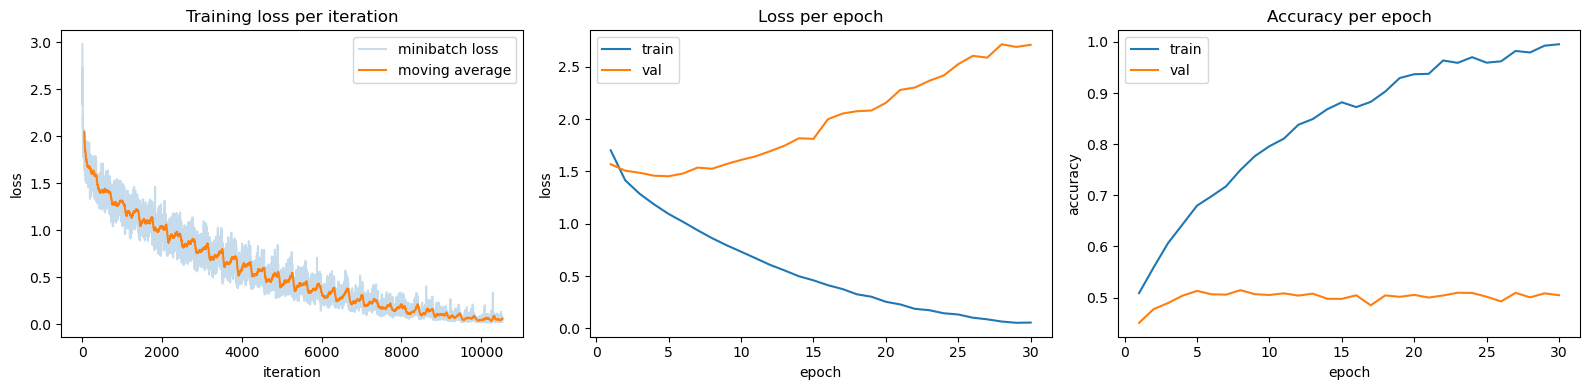

Validation accuracy (final): 50.46%


In [34]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu" 
print(f"Using device: {DEVICE}")

Xtr_d, ytr_d = Xtr.to(DEVICE), ytr.to(DEVICE)
Xva_d, yva_d = Xva.to(DEVICE), yva.to(DEVICE)
Xtr_f = Xtr_d.reshape(len(Xtr_d), -1)          # flatten to 3072-d vectors
Xva_f = Xva_d.reshape(len(Xva_d), -1)

@torch.no_grad()
def mlp_accuracy(net, X, y, bs=5000):
    correct = 0
    for i in range(0, len(X), bs):
        correct += (net.logits(X[i:i + bs]).argmax(1) == y[i:i + bs]).sum().item()
    return correct / len(X)

@torch.no_grad()
def mlp_eval_loss(net, X, y, bs=5000):
    tot = 0.0
    for i in range(0, len(X), bs):
        tot += net.loss(X[i:i + bs], y[i:i + bs]).item() * len(X[i:i + bs])
    return tot / len(X)

@torch.no_grad()
def train_mlp_sgd(net, Xtr, ytr, Xva, yva, lr=0.05, epochs=30, bs=128, seed=0):
    g = torch.Generator().manual_seed(seed)
    hist = dict(iter_loss=[], train_loss=[], val_loss=[], train_acc=[], val_acc=[])
    for ep in range(epochs):
        order = torch.randperm(len(Xtr), generator=g).to(Xtr.device)
        run = []
        for i in range(0, len(Xtr) - bs + 1, bs):
            idx = order[i:i + bs]
            loss = net.loss(Xtr[idx], ytr[idx])
            net.backward()
            for p, gr in zip(net.params(), net.grads()):
                p -= lr * gr                                   # plain SGD step, in place
            run.append(loss.item())
        hist["iter_loss"] += run
        hist["train_loss"].append(float(np.mean(run)))
        hist["val_loss"].append(mlp_eval_loss(net, Xva, yva))
        hist["train_acc"].append(mlp_accuracy(net, Xtr, ytr))
        hist["val_acc"].append(mlp_accuracy(net, Xva, yva))
        # print(f"ep {ep+1:2d}  train loss {hist['train_loss'][-1]:.4f}  "
        #       f"val loss {hist['val_loss'][-1]:.4f}  val acc {hist['val_acc'][-1]:.4f}")
    return hist

# train a 3-layer MLP on CIFAR-10 with SGD
set_seed(SEED)
mlp = MLP([3072, 512, 256, 10], act="relu", init="kaiming", device=DEVICE)
t0 = time.time()
h1 = train_mlp_sgd(mlp, Xtr_f, ytr_d, Xva_f, yva_d, lr=0.05, epochs=30, bs=128)
print(f"done in {time.time()-t0:.0f}s   final val acc = {h1['val_acc'][-1]:.4f}   best = {max(h1['val_acc']):.4f}")

# Plot the training history
def smooth(v, k=50):
    k = min(k, len(v))
    return np.convolve(v, np.ones(k) / k, mode="valid")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sm = smooth(h1["iter_loss"])
ax[0].plot(h1["iter_loss"], alpha=0.25, label="minibatch loss")
ax[0].plot(np.arange(len(h1["iter_loss"]) - len(sm), len(h1["iter_loss"])), sm, label="moving average")
ax[0].set_xlabel("iteration"); ax[0].set_ylabel("loss"); ax[0].set_title("Training loss per iteration"); ax[0].legend()

ep = np.arange(1, len(h1["train_loss"]) + 1)
ax[1].plot(ep, h1["train_loss"], label="train"); ax[1].plot(ep, h1["val_loss"], label="val")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("loss"); ax[1].set_title("Loss per epoch"); ax[1].legend()

ax[2].plot(ep, h1["train_acc"], label="train"); ax[2].plot(ep, h1["val_acc"], label="val")
ax[2].set_xlabel("epoch"); ax[2].set_ylabel("accuracy"); ax[2].set_title("Accuracy per epoch"); ax[2].legend()
plt.tight_layout(); plt.show()
print(f"Validation accuracy (final): {h1['val_acc'][-1]*100:.2f}%")

### 1(d) Per-layer gradient norms at initialisation: sigmoid vs ReLU

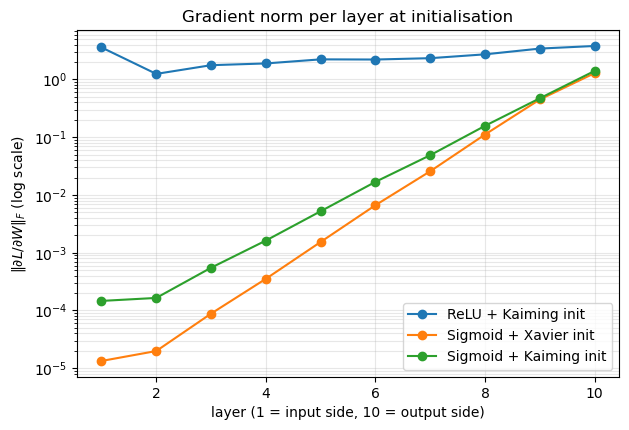

ReLU + Kaiming init      layer10 / layer1 gradient-norm ratio = 1.059e+00
Sigmoid + Xavier init    layer10 / layer1 gradient-norm ratio = 9.645e+04
Sigmoid + Kaiming init   layer10 / layer1 gradient-norm ratio = 9.607e+03


In [33]:
def layer_grad_norms(act, init, depth=10, width=256, bs=256, seed=0):
    set_seed(seed)
    net = MLP([3072] + [width] * (depth - 1) + [10], act=act, init=init, device=DEVICE)
    X, y = Xtr_f[:bs], ytr_d[:bs]
    net.loss(X, y)
    net.backward()
    return [l.dW.norm().item() for l in net.linear_layers()]

configs = [("ReLU + Kaiming init",    "relu",    "kaiming"),
           ("Sigmoid + Xavier init",  "sigmoid", "xavier"),
           ("Sigmoid + Kaiming init", "sigmoid", "kaiming")]
res1d = {name: layer_grad_norms(a, i) for name, a, i in configs}

plt.figure(figsize=(7, 4.5))
for name, norms in res1d.items():
    plt.semilogy(range(1, 11), norms, marker="o", label=name)
plt.xlabel("layer (1 = input side, 10 = output side)"); plt.ylabel(r"$\|\partial L/\partial W\|_F$ (log scale)")
plt.title("Gradient norm per layer at initialisation"); plt.grid(True, which="both", alpha=0.3); plt.legend()
plt.show()

for name, norms in res1d.items():
    print(f"{name:24s} layer10 / layer1 gradient-norm ratio = {norms[-1]/norms[0]:.3e}")

## **Task 02** 

### 2(a): SGD with momentum and Adam Optimizer

In [49]:
# SGD with momentum 
class SGDwithMomentum(Optimizer):
    def __init__(self, params, lr=0.01, momentum=0.9, weight_decay=0.0, nesterov=False):
        defaults = dict(lr=lr, momentum=momentum, weight_decay=weight_decay, nesterov=nesterov)
        super().__init__(params, defaults)
        
    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, mu, wd, nesterov = group["lr"], group["momentum"], group["weight_decay"], group["nesterov"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                g = p.grad
                if wd !=0:
                    g = g.add(p, alpha=wd)
                if mu != 0:
                    state = self.state[p]
                    if "momentum_buffer" not  in state:
                        state["momentum_buffer"] = torch.zeros_like(p)
                    buf = state["momentum_buffer"]
                    buf.mul_(mu).add_(g)
                    g = g.add(buf, alpha=mu) if nesterov else buf
                p.add_(g, alpha=-lr)
        return loss

# Adam optimizer
class AdamOp(Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, (b1, b2), eps, wd = group["lr"], group["betas"], group["eps"], group["weight_decay"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                g = p.grad
                if wd != 0:
                    g = g.add(p, alpha=wd)
                state = self.state[p]
                if len(state) == 0:
                    state["step"] = 0
                    state["exp_avg"] = torch.zeros_like(p)
                    state["exp_avg_sq"] = torch.zeros_like(p)
                state["step"] += 1
                t = state["step"]
                m, v = state["exp_avg"], state["exp_avg_sq"]
                m.mul_(b1).add_(g, alpha=1 - b1)                       # first moment
                v.mul_(b2).addcmul_(g, g, value=1 - b2)                # second moment
                bc1, bc2 = 1 - b1 ** t, 1 - b2 ** t                    # bias corrections
                denom = (v.sqrt() / math.sqrt(bc2)).add_(eps)
                p.addcdiv_(m, denom, value=-lr / bc1)
        return loss
    
    
# Check Optimizer with torch.optim.Optimizer subclasses
def check_optimizer(make_mine, make_ref, steps=50, seed=0):
    torch.manual_seed(seed)
    base = nn.Sequential(nn.Linear(20, 32), nn.Tanh(), nn.Linear(32, 10)).double()
    m1, m2 = deepcopy(base), deepcopy(base)
    o1, o2 = make_mine(m1.parameters()), make_ref(m2.parameters())
    X = torch.randn(256, 20, dtype=torch.float64); y = torch.randint(0, 10, (256,))
    for _ in range(steps):
        idx = torch.randint(0, 256, (32,))                       # SAME minibatch for both models
        for m, o in ((m1, o1), (m2, o2)):
            o.zero_grad()
            F.cross_entropy(m(X[idx]), y[idx]).backward()
            o.step()
    max_diff = max((p1 - p2).abs().max().item() for p1, p2 in zip(m1.parameters(), m2.parameters()))
    ok = all(torch.allclose(p1, p2, rtol=1e-8, atol=1e-10) for p1, p2 in zip(m1.parameters(), m2.parameters()))
    return max_diff, ok

cases = [
    ("SGD lr=0.1",
     lambda ps: SGDwithMomentum(ps, lr=0.1, momentum=0.0),                     lambda ps: torch.optim.SGD(ps, lr=0.1)),
    ("SGD + momentum 0.9",
     lambda ps: SGDwithMomentum(ps, lr=0.05, momentum=0.9),                    lambda ps: torch.optim.SGD(ps, lr=0.05, momentum=0.9)),
    ("SGD + momentum + wd + Nesterov",
     lambda ps: SGDwithMomentum(ps, lr=0.05, momentum=0.9, weight_decay=5e-4, nesterov=True),
     lambda ps: torch.optim.SGD(ps, lr=0.05, momentum=0.9, weight_decay=5e-4, nesterov=True)),
    ("Adam",
     lambda ps: AdamOp(ps, lr=1e-2),                                 lambda ps: torch.optim.Adam(ps, lr=1e-2)),
    ("Adam + wd (L2)",
     lambda ps: AdamOp(ps, lr=1e-2, weight_decay=1e-3),              lambda ps: torch.optim.Adam(ps, lr=1e-2, weight_decay=1e-3)),
]
print(f"{'case':34s}{'max |param diff|':>18s}{'allclose':>10s}")
for name, mine, ref in cases:
    d, ok = check_optimizer(mine, ref)
    print(f"{name:34s}{d:18.2e}{str(ok):>10s}")

case                                max |param diff|  allclose
SGD lr=0.1                                  0.00e+00      True
SGD + momentum 0.9                          0.00e+00      True
SGD + momentum + wd + Nesterov              0.00e+00      True
Adam                                        1.67e-16      True
Adam + wd (L2)                              1.39e-16      True


### 2(b): Trajectories on an ill-conditioned quadratic

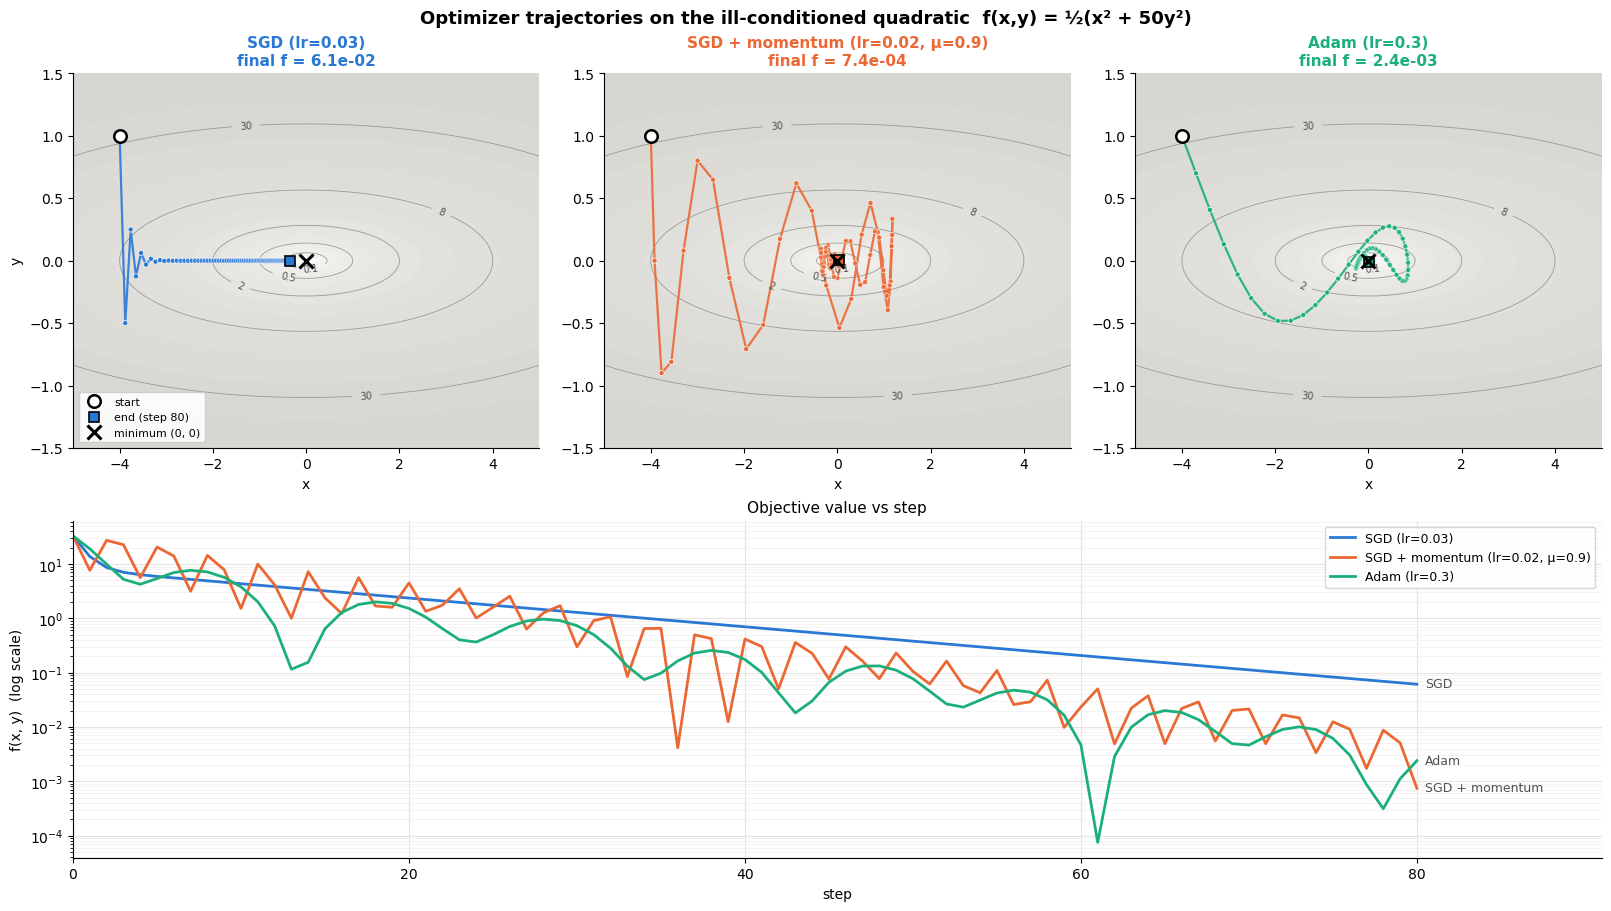

SGD (lr=0.03)                      final f = 6.117e-02   final point = (-0.3498, +0.0000)
SGD + momentum (lr=0.02, μ=0.9)    final f = 7.439e-04   final point = (+0.0278, +0.0038)
Adam (lr=0.3)                      final f = 2.388e-03   final point = (+0.0013, -0.0098)


In [50]:
from matplotlib.colors import LogNorm, LinearSegmentedColormap

def f_toy(p):
    return 0.5 * (p[0] ** 2 + 50.0 * p[1] ** 2)

def run_toy(opt_fn, steps=80, start=(-4.0, 1.0)):
    p = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    opt = opt_fn([p])
    traj, fvals = [p.detach().clone()], [f_toy(p).item()]
    for _ in range(steps):
        opt.zero_grad()
        loss = f_toy(p)
        loss.backward()
        opt.step()
        traj.append(p.detach().clone()); fvals.append(f_toy(p).item())
    return torch.stack(traj).numpy(), np.array(fvals)

toy = {
    "SGD (lr=0.03)":                   run_toy(lambda ps: SGDwithMomentum(ps, lr=0.03, momentum=0.0)),
    "SGD + momentum (lr=0.02, μ=0.9)": run_toy(lambda ps: SGDwithMomentum(ps, lr=0.02, momentum=0.9)),
    "Adam (lr=0.3)":                   run_toy(lambda ps: AdamOp(ps, lr=0.3)),
}
colors = ["#2a78d6", "#eb6834", "#1baf7a"]          # blue, orange, aqua

# loss surface on a grid
xs, ys = np.meshgrid(np.linspace(-5, 5, 500), np.linspace(-1.5, 1.5, 300))
zs = 0.5 * (xs ** 2 + 50.0 * ys ** 2)
levels = np.geomspace(1e-2, zs.max(), 18)
label_levels = [0.1, 0.5, 2, 8, 30]
# light neutral surface: low loss = near-white, high loss = soft grey
surface_cmap = LinearSegmentedColormap.from_list("surface", ["#fcfcfb", "#d6d5cf"])

fig = plt.figure(figsize=(16, 9), constrained_layout=True)
gs = fig.add_gridspec(2, 3, height_ratios=[1, 0.9])

# top row: one panel per optimizer, same surface and limits
for k, ((name, (traj, fv)), c) in enumerate(zip(toy.items(), colors)):
    ax = fig.add_subplot(gs[0, k])
    ax.contourf(xs, ys, zs, levels=levels, norm=LogNorm(), cmap=surface_cmap)
    cs = ax.contour(xs, ys, zs, levels=label_levels, colors="#9b9a95", linewidths=0.6)
    ax.clabel(cs, inline=True, fontsize=7, fmt="%g", colors="#52514e")
    ax.plot(traj[:, 0], traj[:, 1], "-", color=c, lw=1.6, alpha=0.9, zorder=3)
    ax.scatter(traj[:, 0], traj[:, 1], s=14, color=c, edgecolor="white", linewidth=0.5,
               alpha=np.linspace(1.0, 0.35, len(traj)), zorder=4)
    ax.plot(*traj[0], "o", ms=9, mfc="white", mec="black", mew=1.8, zorder=5, label="start")
    ax.plot(*traj[-1], "s", ms=7, mfc=c, mec="black", mew=1.2, zorder=5, label=f"end (step {len(traj)-1})")
    ax.plot(0, 0, "x", ms=10, mew=2.2, color="black", zorder=5, label="minimum (0, 0)")
    ax.set_xlim(-5, 5); ax.set_ylim(-1.5, 1.5)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_title(f"{name}\nfinal f = {fv[-1]:.1e}", fontsize=11, color=c, fontweight="bold")
    ax.set_xlabel("x")
    if k == 0:
        ax.set_ylabel("y")
        ax.legend(loc="lower left", fontsize=8, framealpha=0.9)

# bottom row: objective vs step, all optimizers together
ax = fig.add_subplot(gs[1, :])
for (name, (traj, fv)), c in zip(toy.items(), colors):
    ax.semilogy(fv, color=c, lw=2, label=name)
    ax.annotate(name.split(" (")[0], xy=(len(fv) - 1, fv[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9, color="#52514e")
ax.set_xlim(0, len(fv) + 10)
ax.set_xlabel("step"); ax.set_ylabel("f(x, y)  (log scale)")
ax.set_title("Objective value vs step", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(True, which="major", color="#e5e4e0", lw=0.8); ax.grid(True, which="minor", color="#f0efec", lw=0.5)
ax.legend(fontsize=9, loc="upper right")

fig.suptitle("Optimizer trajectories on the ill-conditioned quadratic  f(x,y) = ½(x² + 50y²)",
             fontsize=13, fontweight="bold")
plt.show()
for name, (traj, fv) in toy.items():
    print(f"{name:34s} final f = {fv[-1]:.3e}   final point = ({traj[-1,0]:+.4f}, {traj[-1,1]:+.4f})")

### 2(c): Small CNN trained with each optimizer at three learning rates

In [51]:
# Small CNN: three conv-ReLU-maxpool blocks (32/64/128 channels) + a 2-layer classifier head.
# No batch norm here on purpose, so the optimizer / learning rate is the only thing that changes.
class SmallCNN(nn.Module):
    def __init__(self, channels=(32, 64, 128), hidden=256, n_classes=10):
        super().__init__()
        layers, c_in = [], 3
        for c_out in channels:
            layers += [nn.Conv2d(c_in, c_out, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2)]
            c_in = c_out
        self.features = nn.Sequential(*layers)                         # 32x32 -> 16 -> 8 -> 4
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(c_in * 4 * 4, hidden), nn.ReLU(inplace=True),
            nn.Linear(hidden, n_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

print(f"SmallCNN parameters: {sum(p.numel() for p in SmallCNN().parameters()):,}")


@torch.no_grad()
def evaluate(model, X, y, bs=1000):
    model.eval()
    tot_loss, correct = 0.0, 0
    for i in range(0, len(X), bs):
        out = model(X[i:i + bs])
        tot_loss += F.cross_entropy(out, y[i:i + bs], reduction="sum").item()
        correct += (out.argmax(1) == y[i:i + bs]).sum().item()
    return tot_loss / len(X), correct / len(X)


def train_cnn(make_opt, lr, epochs=15, bs=128, seed=SEED):
    """Train a fresh SmallCNN. Same seed -> same initial weights and same minibatch order for every run,
    so the optimizer and the learning rate are the only differences between runs."""
    set_seed(seed)
    model = SmallCNN().to(DEVICE)
    opt = make_opt(model.parameters(), lr)
    g = torch.Generator().manual_seed(seed)
    hist = dict(iter_loss=[], train_loss=[], val_loss=[], val_acc=[], diverged=False)
    for ep in range(epochs):
        model.train()
        order = torch.randperm(len(Xtr_d), generator=g).to(DEVICE)
        run = []
        for i in range(0, len(Xtr_d) - bs + 1, bs):
            idx = order[i:i + bs]
            loss = F.cross_entropy(model(Xtr_d[idx]), ytr_d[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
            run.append(loss.item())
            if not math.isfinite(run[-1]):                     # loss blew up: stop this run
                hist["diverged"] = True
                break
        hist["iter_loss"] += run
        hist["train_loss"].append(float(np.mean(run)))
        vl, va = evaluate(model, Xva_d, yva_d)
        hist["val_loss"].append(vl); hist["val_acc"].append(va)
        if hist["diverged"]:
            break
    return hist


# Three learning rates per optimizer, each 10x apart.
# Momentum (mu=0.9) multiplies the effective step by about 1/(1-mu) = 10, so its grid sits 10x below plain SGD.
optimizers = {
    "SGD":            (lambda ps, lr: SGDwithMomentum(ps, lr=lr, momentum=0.0), [0.01, 0.1, 1.0]),
    "SGD + momentum": (lambda ps, lr: SGDwithMomentum(ps, lr=lr, momentum=0.9), [0.001, 0.01, 0.1]),
    "Adam":           (lambda ps, lr: AdamOp(ps, lr=lr),                        [1e-4, 1e-3, 1e-2]),
}
EPOCHS_2C = 15

results_2c = {}                                             # (optimizer, lr) -> history
t0 = time.time()
for name, (make_opt, lrs) in optimizers.items():
    for lr in lrs:
        t = time.time()
        h = train_cnn(make_opt, lr, epochs=EPOCHS_2C)
        results_2c[(name, lr)] = h
        status = "DIVERGED" if h["diverged"] else f"final val acc {h['val_acc'][-1]:.4f}  best {max(h['val_acc']):.4f}"
        print(f"{name:15s} lr={lr:<7g} {status}   ({time.time() - t:.0f}s)")
print(f"total {time.time() - t0:.0f}s")


SmallCNN parameters: 620,362
SGD             lr=0.01    final val acc 0.6204  best 0.6204   (16s)
SGD             lr=0.1     final val acc 0.7030  best 0.7514   (16s)
SGD             lr=1       DIVERGED   (0s)
SGD + momentum  lr=0.001   final val acc 0.6366  best 0.6366   (16s)
SGD + momentum  lr=0.01    final val acc 0.7500  best 0.7572   (16s)
SGD + momentum  lr=0.1     final val acc 0.4838  best 0.6258   (15s)
Adam            lr=0.0001  final val acc 0.6852  best 0.6852   (18s)
Adam            lr=0.001   final val acc 0.7434  best 0.7576   (19s)
Adam            lr=0.01    final val acc 0.4980  best 0.5132   (18s)
total 133s


optimizer,lr,final_train_loss,final_val_acc,best_val_acc,best_epoch,diverged
SGD,0.01,1.035,62.04%,62.04%,15,False
SGD,0.1,0.097,70.30%,75.14%,11,False
SGD,1,nan,9.64%,9.64%,1,True
SGD + momentum,0.001,1.005,63.66%,63.66%,15,False
SGD + momentum,0.01,0.092,75.00%,75.72%,14,False
SGD + momentum,0.1,1.334,48.38%,62.58%,6,False
Adam,0.0001,0.838,68.52%,68.52%,15,False
Adam,0.001,0.075,74.34%,75.76%,6,False
Adam,0.01,1.272,49.80%,51.32%,13,False


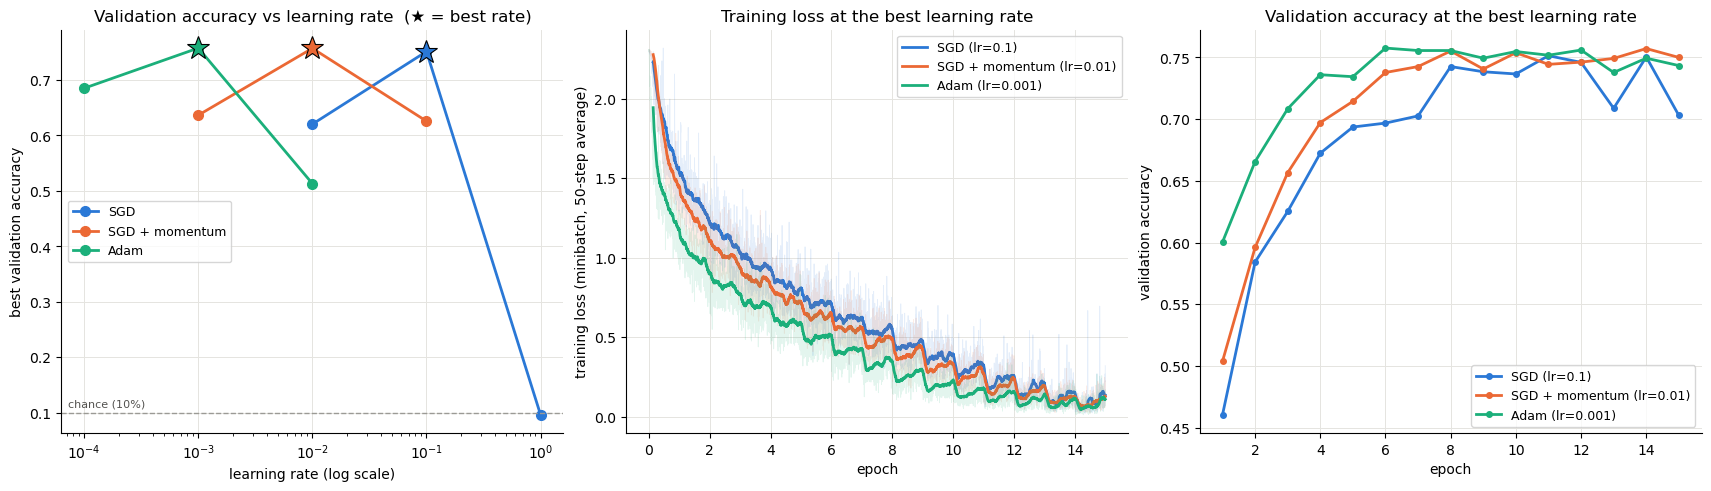

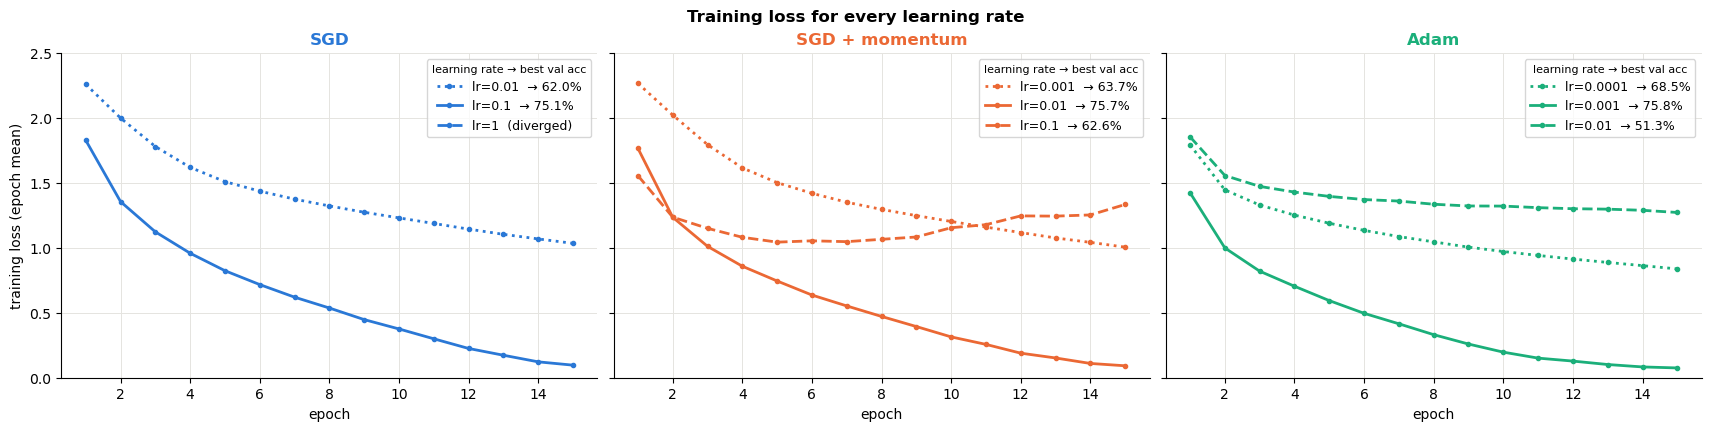

SGD             best lr = 0.1     best val acc = 75.14%   spread across its 3 rates = 65.5 points
SGD + momentum  best lr = 0.01    best val acc = 75.72%   spread across its 3 rates = 13.1 points
Adam            best lr = 0.001   best val acc = 75.76%   spread across its 3 rates = 24.4 points


In [52]:
opt_colors = {"SGD": "#2a78d6", "SGD + momentum": "#eb6834", "Adam": "#1baf7a"}   # same colours as 2(b)
lr_styles = [":", "-", "--"]                                                       # low / mid / high lr
peak = lambda h: max(h["val_acc"])                     # validation accuracy used to pick the best rate

# ---- summary table ----
rows = []
for (name, lr), h in results_2c.items():
    rows.append(dict(optimizer=name, lr=lr, final_train_loss=h["train_loss"][-1],
                     final_val_acc=h["val_acc"][-1], best_val_acc=peak(h),
                     best_epoch=int(np.argmax(h["val_acc"])) + 1, diverged=h["diverged"]))
df_2c = pd.DataFrame(rows)
best_lr = {name: df_2c[df_2c.optimizer == name].sort_values("best_val_acc").iloc[-1].lr for name in optimizers}
display(df_2c.style.format({"lr": "{:g}", "final_train_loss": "{:.3f}",
                            "final_val_acc": "{:.2%}", "best_val_acc": "{:.2%}"}).hide(axis="index"))

# ---- figure 1: sensitivity + behaviour at the best rate ----
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8), constrained_layout=True)

for name, (_, lrs) in optimizers.items():
    c = opt_colors[name]
    accs = [peak(results_2c[(name, lr)]) for lr in lrs]
    ax[0].semilogx(lrs, accs, "-o", color=c, lw=2, ms=7, label=name)
    b = lrs.index(best_lr[name])
    ax[0].plot(lrs[b], accs[b], "*", ms=17, color=c, mec="black", mew=0.8, zorder=5)
ax[0].axhline(0.10, color="#9b9a95", ls="--", lw=1)
ax[0].text(ax[0].get_xlim()[0] * 1.15, 0.11, "chance (10%)", fontsize=8, color="#52514e")
ax[0].set_xlabel("learning rate (log scale)"); ax[0].set_ylabel("best validation accuracy")
ax[0].set_title("Validation accuracy vs learning rate  (★ = best rate)")
ax[0].legend(fontsize=9)

for name in optimizers:
    h, c = results_2c[(name, best_lr[name])], opt_colors[name]
    it = np.asarray(h["iter_loss"])
    ipe = len(it) / len(h["train_loss"])                                   # iterations per epoch
    k = 50
    sm = np.convolve(it, np.ones(k) / k, mode="valid")
    ax[1].plot(np.arange(len(it)) / ipe, it, color=c, alpha=0.12, lw=0.6)
    ax[1].plot((np.arange(len(sm)) + k - 1) / ipe, sm, color=c, lw=2, label=f"{name} (lr={best_lr[name]:g})")
    ep = np.arange(1, len(h["val_acc"]) + 1)
    ax[2].plot(ep, h["val_acc"], "-o", ms=4, color=c, lw=2, label=f"{name} (lr={best_lr[name]:g})")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("training loss (minibatch, 50-step average)")
ax[1].set_title("Training loss at the best learning rate"); ax[1].legend(fontsize=9)
ax[2].set_xlabel("epoch"); ax[2].set_ylabel("validation accuracy")
ax[2].set_title("Validation accuracy at the best learning rate"); ax[2].legend(fontsize=9)
for a in ax:
    a.grid(True, which="major", color="#e5e4e0", lw=0.7); a.spines[["top", "right"]].set_visible(False)
plt.show()

# ---- figure 2: every run, one panel per optimizer ----
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2), sharey=True, constrained_layout=True)
for a, (name, (_, lrs)) in zip(ax, optimizers.items()):
    for lr, ls in zip(lrs, lr_styles):
        h = results_2c[(name, lr)]
        lab = f"lr={lr:g}" + ("  (diverged)" if h["diverged"] else f"  → {peak(h):.1%}")
        a.plot(np.arange(1, len(h["train_loss"]) + 1), h["train_loss"], ls, marker="o", ms=3,
               color=opt_colors[name], lw=2, label=lab)
    a.set_title(name, color=opt_colors[name], fontweight="bold")
    a.set_xlabel("epoch"); a.grid(True, color="#e5e4e0", lw=0.7); a.spines[["top", "right"]].set_visible(False)
    a.legend(fontsize=9, title="learning rate → best val acc", title_fontsize=8)
ax[0].set_ylabel("training loss (epoch mean)")
ax[0].set_ylim(0, 2.5)
fig.suptitle("Training loss for every learning rate", fontweight="bold")
plt.show()

for name in optimizers:
    accs = df_2c[df_2c.optimizer == name].best_val_acc
    print(f"{name:15s} best lr = {best_lr[name]:<7g} best val acc = {accs.max():.2%}   "
          f"spread across its 3 rates = {(accs.max() - accs.min()) * 100:.1f} points")


**Discussion (2c):** _to be written_

## **Task 03**

### 3(a): Regularisation of a small CNN with batch norm on 5k training images

CNNBN parameters: 551,018   training images: 5000
baseline       train acc 1.0000  val acc 0.6854  (43s)
weight decay   train acc 1.0000  val acc 0.6956  (42s)
dropout        train acc 1.0000  val acc 0.7124  (41s)
flip + crop    train acc 0.9998  val acc 0.7622  (42s)
cutout         train acc 1.0000  val acc 0.7066  (41s)
mixup          train acc 1.0000  val acc 0.6792  (41s)
all combined   train acc 0.8752  val acc 0.7636  (47s)


setting,train_acc,val_acc,gap,best_val_acc
baseline,100.00%,68.54%,31.46%,68.78%
weight decay,100.00%,69.56%,30.44%,69.66%
dropout,100.00%,71.24%,28.76%,71.28%
flip + crop,99.98%,76.22%,23.76%,76.30%
cutout,100.00%,70.66%,29.34%,70.94%
mixup,100.00%,67.92%,32.08%,68.70%
all combined,87.52%,76.36%,11.16%,77.32%


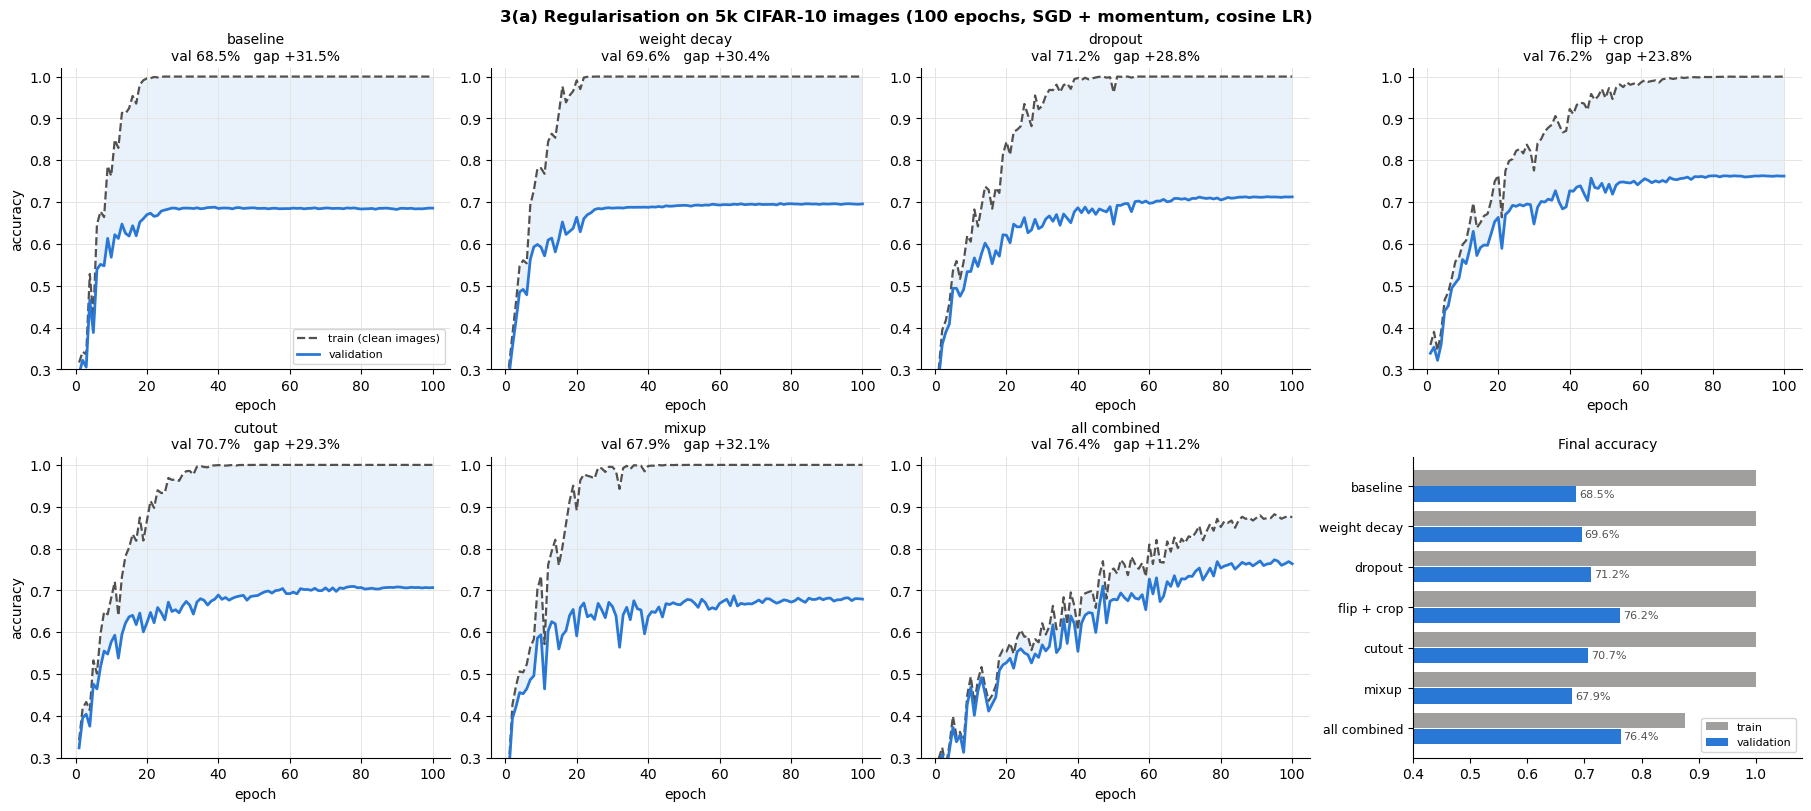

In [53]:
torch.backends.cudnn.benchmark = True
AMP = DEVICE == "cuda"                       # mixed precision on GPU (works on a Colab T4 too)
# GradScaler skips the first optimizer step while it calibrates; that triggers a harmless scheduler-order warning
import warnings
warnings.filterwarnings("ignore", message="Detected call of `lr_scheduler.step\\(\\)` before")

# ---------------- augmentations, implemented on GPU batches ----------------
def flip_crop(x, pad=4):
    """Random horizontal flip + random crop from a zero-padded image (zero = channel mean after normalisation)."""
    N, C, H, W = x.shape
    flip = torch.rand(N, device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    xp = F.pad(x, (pad, pad, pad, pad))
    dy = torch.randint(0, 2 * pad + 1, (N, 1), device=x.device)
    dx = torch.randint(0, 2 * pad + 1, (N, 1), device=x.device)
    rows = (dy + torch.arange(H, device=x.device))[:, :, None]          # (N, H, 1)
    cols = (dx + torch.arange(W, device=x.device))[:, None, :]          # (N, 1, W)
    n = torch.arange(N, device=x.device)[:, None, None]
    return xp.permute(0, 2, 3, 1)[n, rows, cols].permute(0, 3, 1, 2).contiguous()

def cutout(x, size=16):
    """Zero a size x size square at a random centre in every image (the square may be clipped at the border)."""
    N, C, H, W = x.shape
    cy = torch.randint(0, H, (N, 1, 1), device=x.device)
    cx = torch.randint(0, W, (N, 1, 1), device=x.device)
    ys = torch.arange(H, device=x.device)[None, :, None]
    xs = torch.arange(W, device=x.device)[None, None, :]
    hole = (ys >= cy - size // 2) & (ys < cy + size // 2) & (xs >= cx - size // 2) & (xs < cx + size // 2)
    return x * (~hole)[:, None].to(x.dtype)

def mixup(x, y, alpha=1.0):
    """Blend each image with a random partner; the loss is blended with the same weight lam."""
    lam = float(np.random.beta(alpha, alpha))
    perm = torch.randperm(len(x), device=x.device)
    return lam * x + (1 - lam) * x[perm], y, y[perm], lam


# ---------------- one training loop shared by Tasks 3 and 4 ----------------
def fit(model, Xtr, ytr, epochs, lr, wd=0.0, bs=128, aug=(), mixup_alpha=0.0, label_smoothing=0.0,
        schedule="cosine", nesterov=False, eval_train=True, seed=SEED):
    """SGD (momentum 0.9) training with per-step LR schedule. Returns per-epoch history.
    train_acc is measured on the *clean* training images in eval mode, so it is comparable across settings."""
    set_seed(seed)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, nesterov=nesterov, weight_decay=wd)
    steps_per_epoch = len(Xtr) // bs
    total = epochs * steps_per_epoch
    warm = steps_per_epoch                                    # 1 epoch linear warm-up, then cosine decay
    if schedule == "cosine":
        sched = torch.optim.lr_scheduler.LambdaLR(
            opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / (total - warm))))
    elif schedule == "onecycle":
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=total, pct_start=0.25)
    else:                                                     # "constant"
        sched = None
    scaler = torch.amp.GradScaler("cuda", enabled=AMP)
    g = torch.Generator().manual_seed(seed)
    hist = dict(train_loss=[], train_acc=[], val_loss=[], val_acc=[])
    for ep in range(epochs):
        model.train()
        order = torch.randperm(len(Xtr), generator=g).to(Xtr.device)
        run = []
        for i in range(steps_per_epoch):
            idx = order[i * bs:(i + 1) * bs]
            xb, yb = Xtr[idx], ytr[idx]
            for a in aug:
                xb = a(xb)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=AMP):
                if mixup_alpha > 0:
                    xb, ya, yb2, lam = mixup(xb, yb, mixup_alpha)
                    out = model(xb)
                    loss = lam * F.cross_entropy(out, ya, label_smoothing=label_smoothing) \
                           + (1 - lam) * F.cross_entropy(out, yb2, label_smoothing=label_smoothing)
                else:
                    loss = F.cross_entropy(model(xb), yb, label_smoothing=label_smoothing)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            if sched is not None:
                sched.step()
            run.append(loss.item())
        hist["train_loss"].append(float(np.mean(run)))
        if eval_train:
            hist["train_acc"].append(evaluate(model, Xtr, ytr)[1])
        vl, va = evaluate(model, Xva_d, yva_d)
        hist["val_loss"].append(vl); hist["val_acc"].append(va)
    return hist


# ---------------- 3(a): small CNN with batch norm on 5k training images ----------------
class CNNBN(nn.Module):
    """Two conv-BN-ReLU layers per stage (32/64/128 channels), max-pool after each stage, then a small MLP head."""
    def __init__(self, drop=0.0, channels=(32, 64, 128), hidden=128, n_classes=10):
        super().__init__()
        layers, c_in = [], 3
        for c in channels:
            for _ in range(2):
                layers += [nn.Conv2d(c_in, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True)]
                c_in = c
            layers.append(nn.MaxPool2d(2))
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(drop), nn.Linear(c_in * 4 * 4, hidden),
                                  nn.ReLU(inplace=True), nn.Dropout(drop), nn.Linear(hidden, n_classes))

    def forward(self, x):
        return self.head(self.features(x))

# fixed random 5k subset of the 45k training split
sub = torch.randperm(len(Xtr_d), generator=torch.Generator().manual_seed(SEED))[:5000].to(DEVICE)
X5k, y5k = Xtr_d[sub], ytr_d[sub]

WD, DROP, CUT, ALPHA = 5e-4, 0.3, 16, 1.0
settings_3a = {
    "baseline":     dict(),
    "weight decay": dict(wd=WD),
    "dropout":      dict(drop=DROP),
    "flip + crop":  dict(aug=(flip_crop,)),
    "cutout":       dict(aug=(lambda x: cutout(x, CUT),)),
    "mixup":        dict(mixup_alpha=ALPHA),
    "all combined": dict(wd=WD, drop=DROP, aug=(flip_crop, lambda x: cutout(x, CUT)), mixup_alpha=ALPHA),
}
EPOCHS_3A = 100

print(f"CNNBN parameters: {sum(p.numel() for p in CNNBN().parameters()):,}   training images: {len(X5k)}")
results_3a = {}
for name, s in settings_3a.items():
    t = time.time()
    s = dict(s)
    set_seed(SEED)
    model = CNNBN(drop=s.pop("drop", 0.0)).to(DEVICE)
    results_3a[name] = fit(model, X5k, y5k, EPOCHS_3A, lr=0.05, **s)
    h = results_3a[name]
    print(f"{name:14s} train acc {h['train_acc'][-1]:.4f}  val acc {h['val_acc'][-1]:.4f}  ({time.time() - t:.0f}s)")

# ---- table: final-epoch train / val accuracy and the generalisation gap ----
df_3a = pd.DataFrame([dict(setting=n, train_acc=h["train_acc"][-1], val_acc=h["val_acc"][-1],
                           gap=h["train_acc"][-1] - h["val_acc"][-1], best_val_acc=max(h["val_acc"]))
                      for n, h in results_3a.items()])
display(df_3a.style.format({c: "{:.2%}" for c in ["train_acc", "val_acc", "gap", "best_val_acc"]})
        .hide(axis="index"))

# ---- curves: one panel per setting (train dashed, val solid, gap shaded) + summary bars ----
C_TRAIN, C_VAL = "#52514e", "#2a78d6"
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=False, constrained_layout=True)
ep = np.arange(1, EPOCHS_3A + 1)
for a, (name, h) in zip(axes.flat, results_3a.items()):
    tr, va = np.array(h["train_acc"]), np.array(h["val_acc"])
    a.fill_between(ep, va, tr, where=tr >= va, color=C_VAL, alpha=0.10, lw=0)
    a.plot(ep, tr, "--", color=C_TRAIN, lw=1.6, label="train (clean images)")
    a.plot(ep, va, "-", color=C_VAL, lw=2, label="validation")
    a.set_title(f"{name}\nval {va[-1]:.1%}   gap {tr[-1] - va[-1]:+.1%}", fontsize=10)
    a.set_ylim(0.3, 1.02); a.set_xlabel("epoch")
    a.grid(True, color="#e5e4e0", lw=0.7); a.spines[["top", "right"]].set_visible(False)
axes[0, 0].set_ylabel("accuracy"); axes[1, 0].set_ylabel("accuracy")
axes[0, 0].legend(fontsize=8, loc="lower right")

a = axes[1, 3]
yy = np.arange(len(df_3a))[::-1]
a.barh(yy + 0.2, df_3a.train_acc, height=0.38, color=C_TRAIN, alpha=0.55, label="train")
a.barh(yy - 0.2, df_3a.val_acc, height=0.38, color=C_VAL, label="validation")
for y_, v in zip(yy, df_3a.val_acc):
    a.text(v + 0.005, y_ - 0.2, f"{v:.1%}", va="center", fontsize=8, color="#52514e")
a.set_yticks(yy); a.set_yticklabels(df_3a.setting, fontsize=9)
a.set_xlim(0.4, 1.08); a.set_title("Final accuracy", fontsize=10); a.legend(fontsize=8, loc="lower right")
a.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"3(a) Regularisation on 5k CIFAR-10 images ({EPOCHS_3A} epochs, SGD + momentum, cosine LR)",
             fontweight="bold")
plt.show()


**Discussion (3a):** _to be written_

### 3(b): Plain vs residual CIFAR networks (depth 6n+2 = 8, 20, 56)

plain   -8   params  75,290  final train loss 0.3730  val acc 0.8482  (61s)
residual-8   params  75,290  final train loss 0.3891  val acc 0.8458  (62s)
plain   -20  params 269,722  final train loss 0.2180  val acc 0.8686  (122s)
residual-20  params 269,722  final train loss 0.1514  val acc 0.8948  (131s)
plain   -56  params 853,018  final train loss 0.8117  val acc 0.7086  (299s)
residual-56  params 853,018  final train loss 0.0823  val acc 0.9002  (325s)


network,params,final_train_loss,final_val_acc
plain-8,"75,290",0.3730,84.82%
residual-8,"75,290",0.3891,84.58%
plain-20,"269,722",0.2180,86.86%
residual-20,"269,722",0.1514,89.48%
plain-56,"853,018",0.8117,70.86%
residual-56,"853,018",0.0823,90.02%


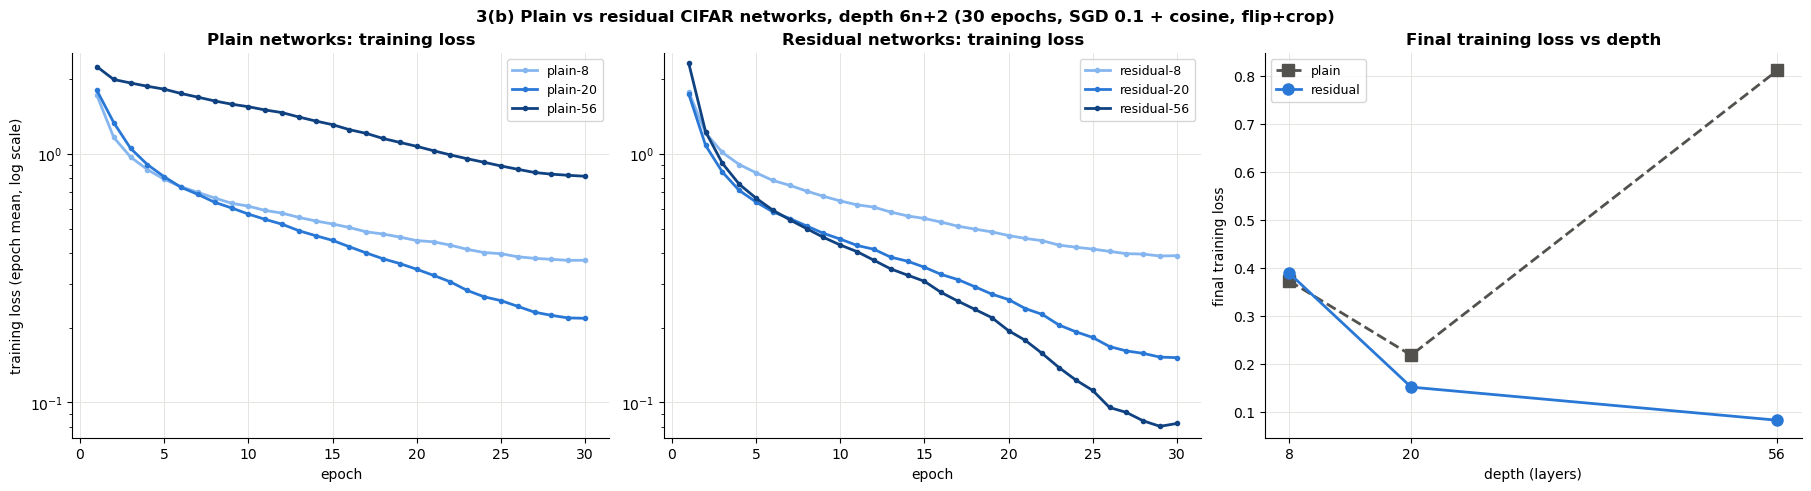

In [54]:
class BasicBlock(nn.Module):
    """conv3x3-BN-ReLU-conv3x3-BN (+ shortcut) -> ReLU.
    The shortcut is parameter-free ('option A' of He et al.): identity, or stride-2 subsampling with zero-padded
    extra channels when the stage changes. So plain and residual networks have exactly the same parameters."""
    def __init__(self, c_in, c_out, stride, residual):
        super().__init__()
        self.residual, self.stride, self.extra = residual, stride, c_out - c_in
        self.conv1 = nn.Conv2d(c_in, c_out, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(c_out)

    def shortcut(self, x):
        if self.stride > 1:
            x = x[:, :, ::self.stride, ::self.stride]
        if self.extra > 0:
            x = F.pad(x, (0, 0, 0, 0, 0, self.extra))
        return x

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            out = out + self.shortcut(x)                         # the ONLY difference between the two families
        return F.relu(out)


class CifarResNet(nn.Module):
    """Depth 6n+2: a 3x3 stem conv, three stages of n blocks (2 convs each), global average pooling, linear layer."""
    def __init__(self, n, residual=True, widths=(16, 32, 64), n_classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, padding=1, bias=False),
                                  nn.BatchNorm2d(widths[0]), nn.ReLU(inplace=True))
        blocks, c_in = [], widths[0]
        for s, c in enumerate(widths):
            for b in range(n):
                blocks.append(BasicBlock(c_in, c, stride=2 if (s > 0 and b == 0) else 1, residual=residual))
                c_in = c
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(c_in, n_classes)
        for m in self.modules():                                 # Kaiming initialisation
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.blocks(self.stem(x))
        return self.fc(F.adaptive_avg_pool2d(x, 1).flatten(1))


EPOCHS_3B = 30
results_3b, params_3b = {}, {}
for depth in (8, 20, 56):
    n = (depth - 2) // 6
    for residual in (False, True):
        key = ("residual" if residual else "plain", depth)
        t = time.time()
        set_seed(SEED)
        model = CifarResNet(n, residual=residual).to(DEVICE)
        params_3b[key] = sum(p.numel() for p in model.parameters())
        results_3b[key] = fit(model, Xtr_d, ytr_d, EPOCHS_3B, lr=0.1, wd=1e-4, aug=(flip_crop,), eval_train=False)
        h = results_3b[key]
        print(f"{key[0]:8s}-{depth:<3d} params {params_3b[key]:>7,}  final train loss {h['train_loss'][-1]:.4f}  "
              f"val acc {h['val_acc'][-1]:.4f}  ({time.time() - t:.0f}s)")

df_3b = pd.DataFrame([dict(network=f"{k[0]}-{k[1]}", params=params_3b[k], final_train_loss=h["train_loss"][-1],
                           final_val_acc=h["val_acc"][-1]) for k, h in results_3b.items()])
display(df_3b.style.format({"params": "{:,}", "final_train_loss": "{:.4f}", "final_val_acc": "{:.2%}"})
        .hide(axis="index"))

# ---- plots: colour = depth (light -> dark), one panel per family, then final loss vs depth ----
depth_colors = {8: "#86b6ef", 20: "#2a78d6", 56: "#104281"}
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8), constrained_layout=True)
ep = np.arange(1, EPOCHS_3B + 1)
for a, fam in zip(ax[:2], ("plain", "residual")):
    for depth, c in depth_colors.items():
        a.semilogy(ep, results_3b[(fam, depth)]["train_loss"], "-o", ms=3, lw=2, color=c, label=f"{fam}-{depth}")
    a.set_title(f"{fam.capitalize()} networks: training loss", fontweight="bold")
    a.set_xlabel("epoch"); a.legend(fontsize=9)
ax[0].set_ylabel("training loss (epoch mean, log scale)")
lo = min(min(h["train_loss"]) for h in results_3b.values()) * 0.9
hi = max(max(h["train_loss"]) for h in results_3b.values()) * 1.1
ax[0].set_ylim(lo, hi); ax[1].set_ylim(lo, hi)

for fam, ls, mk in (("plain", "--", "s"), ("residual", "-", "o")):
    ax[2].plot([8, 20, 56], [results_3b[(fam, d)]["train_loss"][-1] for d in (8, 20, 56)], ls, marker=mk,
               ms=8, lw=2, color="#52514e" if fam == "plain" else "#2a78d6", label=fam)
ax[2].set_xticks([8, 20, 56]); ax[2].set_xlabel("depth (layers)"); ax[2].set_ylabel("final training loss")
ax[2].set_title("Final training loss vs depth", fontweight="bold"); ax[2].legend(fontsize=9)
for a in ax:
    a.grid(True, which="major", color="#e5e4e0", lw=0.7); a.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"3(b) Plain vs residual CIFAR networks, depth 6n+2 ({EPOCHS_3B} epochs, SGD 0.1 + cosine, flip+crop)",
             fontweight="bold")
plt.show()


**Discussion (3b):** _to be written_

## **Task 04** (Optional)
### Best CNN with at most 500k parameters and at most 20 epochs

full recipe                  params 453,476  val acc 0.9044  (92s)
no shortcut (plain)          params 453,476  val acc 0.8950  (86s)
no augmentation              params 453,476  val acc 0.8568  (86s)
no weight decay              params 453,476  val acc 0.8804  (91s)
constant LR (no one-cycle)   params 453,476  val acc 0.7234  (92s)


variant,final_train_loss,val_acc,delta_vs_full
full recipe,0.7534,90.44%,+0.00%
no shortcut (plain),0.7575,89.50%,-0.94%
no augmentation,0.5248,85.68%,-4.76%
no weight decay,0.8001,88.04%,-2.40%
constant LR (no one-cycle),0.9630,72.34%,-18.10%



Final model: 'full recipe'  (453,476 parameters, 20 epochs)
Validation accuracy: 90.44%
TEST accuracy (evaluated once): 89.68%


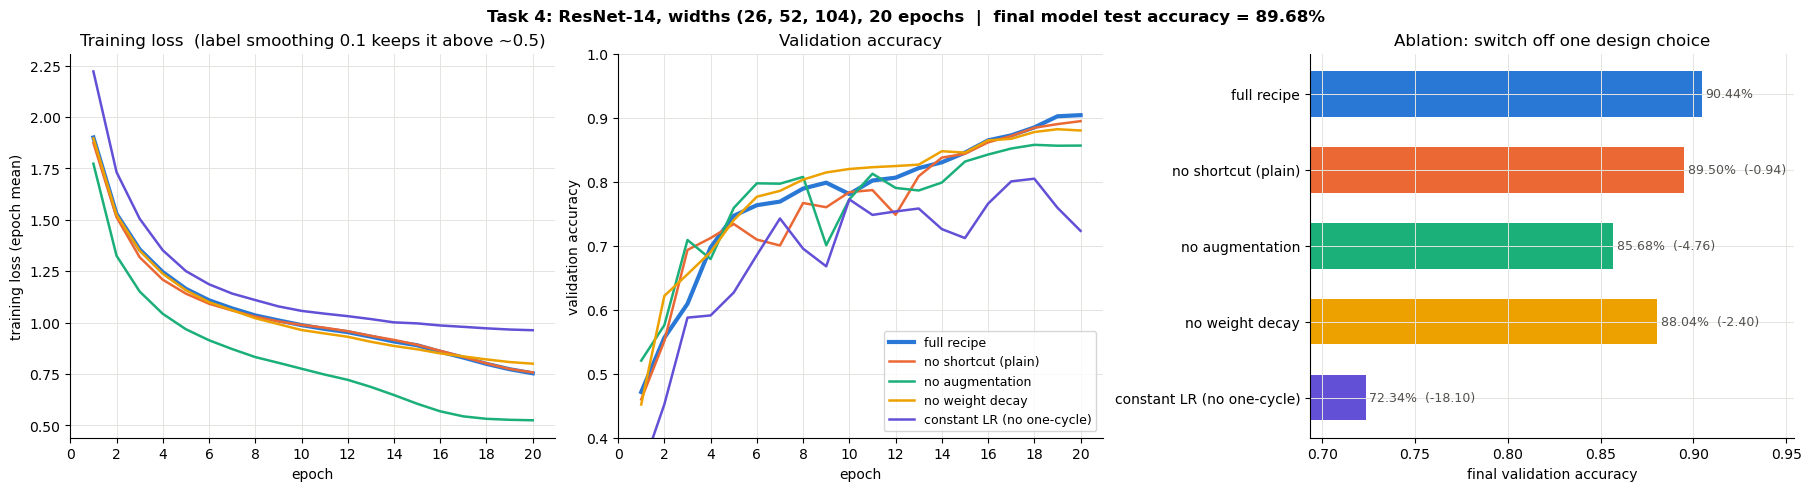

In [55]:
# Final design: a wider CIFAR ResNet (reuses CifarResNet / BasicBlock from 3(b)), trained for 20 epochs.
ARCH_4 = dict(n=2, widths=(26, 52, 104))                    # ResNet-14, ~1.6x wider than the 3(b) networks
EPOCHS_4, MAX_PARAMS = 20, 500_000

full_recipe = dict(residual=True, aug=True, wd=5e-4, schedule="onecycle")
# ablation: start from the full recipe and switch off ONE design choice at a time
variants_4 = {
    "full recipe":                full_recipe,
    "no shortcut (plain)":        {**full_recipe, "residual": False},
    "no augmentation":            {**full_recipe, "aug": False},
    "no weight decay":            {**full_recipe, "wd": 0.0},
    "constant LR (no one-cycle)": {**full_recipe, "schedule": "constant"},
}

def run_variant(v):
    set_seed(SEED)
    model = CifarResNet(ARCH_4["n"], residual=v["residual"], widths=ARCH_4["widths"]).to(DEVICE)
    n_params = sum(p.numel() for p in model.parameters())
    assert n_params <= MAX_PARAMS, n_params
    aug = (flip_crop, lambda x: cutout(x, 12)) if v["aug"] else ()
    h = fit(model, Xtr_d, ytr_d, EPOCHS_4, lr=0.1, wd=v["wd"], aug=aug, label_smoothing=0.1,
            schedule=v["schedule"], nesterov=True, eval_train=False)
    return model, h, n_params

results_4, models_4 = {}, {}
for name, v in variants_4.items():
    t = time.time()
    models_4[name], results_4[name], n_params = run_variant(v)
    print(f"{name:28s} params {n_params:,}  val acc {results_4[name]['val_acc'][-1]:.4f}  ({time.time() - t:.0f}s)")

# ---- ablation table (validation only) ----
ref = results_4["full recipe"]["val_acc"][-1]
df_4 = pd.DataFrame([dict(variant=n, final_train_loss=h["train_loss"][-1], val_acc=h["val_acc"][-1],
                          delta_vs_full=h["val_acc"][-1] - ref) for n, h in results_4.items()])
display(df_4.style.format({"final_train_loss": "{:.4f}", "val_acc": "{:.2%}", "delta_vs_full": "{:+.2%}"})
        .hide(axis="index"))

# ---- pick the final model on VALIDATION accuracy, then use the test set exactly once ----
final_name = df_4.sort_values("val_acc").iloc[-1].variant
final_model = models_4[final_name]
Xte_d, yte_d = Xte.to(DEVICE), yte.to(DEVICE)
test_loss, test_acc = evaluate(final_model, Xte_d, yte_d)
print(f"\nFinal model: '{final_name}'  ({sum(p.numel() for p in final_model.parameters()):,} parameters, "
      f"{EPOCHS_4} epochs)")
print(f"Validation accuracy: {results_4[final_name]['val_acc'][-1]:.2%}")
print(f"TEST accuracy (evaluated once): {test_acc:.2%}")

# ---- plots ----
var_colors = dict(zip(variants_4, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6"]))
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8), constrained_layout=True)
ep = np.arange(1, EPOCHS_4 + 1)
for name, h in results_4.items():
    lw = 3 if name == "full recipe" else 1.8
    ax[0].plot(ep, h["train_loss"], lw=lw, color=var_colors[name], label=name)
    ax[1].plot(ep, h["val_acc"], lw=lw, color=var_colors[name], label=name)
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("training loss (epoch mean)")
ax[0].set_title("Training loss  (label smoothing 0.1 keeps it above ~0.5)")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation accuracy"); ax[1].set_title("Validation accuracy")
ax[1].set_ylim(0.4, 1.0); ax[1].legend(fontsize=9, loc="lower right")
for a in ax[:2]:
    a.set_xticks(range(0, EPOCHS_4 + 1, max(1, EPOCHS_4 // 10)))

yy = np.arange(len(df_4))[::-1]
ax[2].barh(yy, df_4.val_acc, color=[var_colors[n] for n in df_4.variant], height=0.6)
for y_, v, d in zip(yy, df_4.val_acc, df_4.delta_vs_full):
    ax[2].text(v + 0.002, y_, f"{v:.2%}" + ("" if abs(d) < 1e-12 else f"  ({d * 100:+.2f})"),
               va="center", fontsize=9, color="#52514e")
ax[2].set_yticks(yy); ax[2].set_yticklabels(df_4.variant)
lo = df_4.val_acc.min() - 0.03
ax[2].set_xlim(lo, df_4.val_acc.max() + 0.05); ax[2].set_xlabel("final validation accuracy")
ax[2].set_title("Ablation: switch off one design choice")
for a in ax:
    a.grid(True, color="#e5e4e0", lw=0.7); a.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"Task 4: ResNet-{6 * ARCH_4['n'] + 2}, widths {ARCH_4['widths']}, {EPOCHS_4} epochs  |  "
             f"final model test accuracy = {test_acc:.2%}", fontweight="bold")
plt.show()


**Discussion (4):** _to be written_